In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, MaxNLocator

from scipy.integrate import solve_ivp

import numcosmo_II
from numcosmo_II import FLRW
from numcosmo_II.spherical_collapse import (
    SphericalCollapse,
    CollapseThreshold,
)

def growth_rate(cosmology, growth_sol, ai):
    """
    Calculate f = dln(D)/dln(a) at ai.
    """
    _, f_i = cosmology.get_growth_observables(
        growth_sol,
        N_eval=np.array([np.log(ai)]),
    )

    return float(f_i[0])
    
def lambda_ta_background(Omega_m0, a_ta, zeta_ta):
    """lambda_ta = rho_Lambda/rho_sph,ta, with rho_sph,ta=zeta_ta*rho_m(a_ta)."""
    omega_m_a = Omega_m0 / (Omega_m0 + (1.0 - Omega_m0) * a_ta**3)
    omega_l_a = 1.0 - omega_m_a
    return omega_l_a / (zeta_ta * omega_m_a)

def physical_virial_root(lambda_ta):
    """Real physical root 0<y<=1 connected continuously to y=1/2 at lambda_ta=0."""
    lam = float(lambda_ta)
    if not np.isfinite(lam) or lam < 0.0:
        raise ValueError(f"lambda_ta must be finite and non-negative; got {lam}")
    if abs(lam) < 1e-14:
        return 0.5
    roots = np.roots([4.0*lam, 0.0, -2.0*(1.0+lam), 1.0])
    # For lambda_ta >= 0, the physical branch continuously connected to
    # the EdS solution y=1/2 lies at 0 < y <= 1/2.
    candidates = [float(r.real) for r in roots
                  if abs(r.imag) < 1e-8 and 0.0 < r.real <= 0.5 + 1e-10]
    if not candidates:
        raise RuntimeError(f"No physical virial root on the EdS-connected branch for lambda_ta={lam}; roots={roots}")
    root = max(candidates)
    residual = 4.0*lam*root**3 - 2.0*(1.0+lam)*root + 1.0
    if abs(residual) > 1e-8:
        raise RuntimeError(f"Virial polynomial residual too large: {residual}")
    return root

N_i = -4.605170
delta_i = 1.000000e-04
f_i = 1.000000
delta_N,i = 1.000000e-04
theta_i = -9.999000e-05
g_i = 1.000000e+04


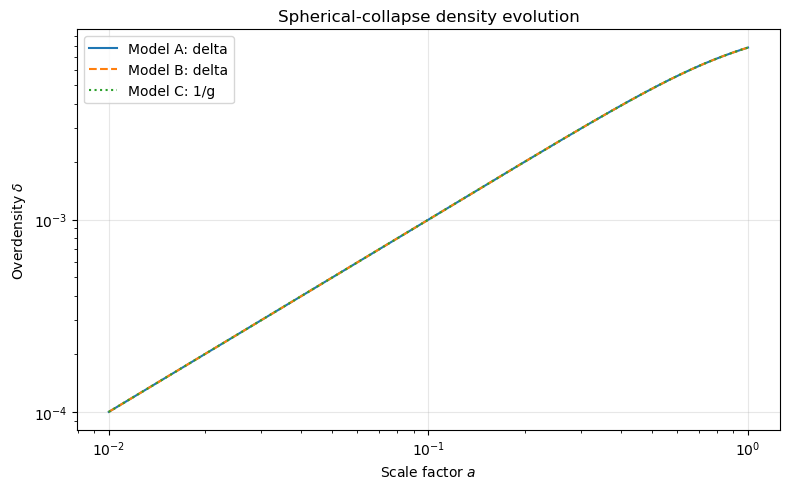

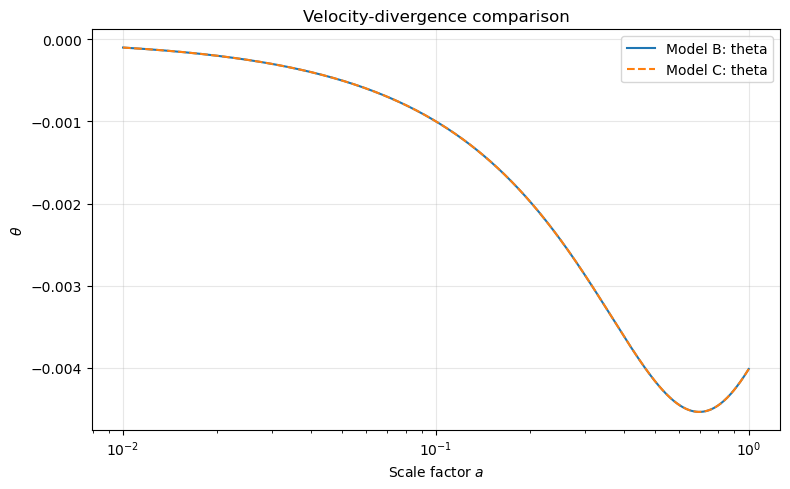

Model A: delta(a_i) = 1.000000e-04, delta(a_f) = 7.838410e-03
Model B: delta(a_i) = 1.000000e-04, delta(a_f) = 7.838410e-03
Model C: delta(a_i) = 1.000000e-04, delta(a_f) = 7.838408e-03


In [1]:
cosmology = FLRW(
    h=0.67,
    Omega_m=0.3,
    Omega_lambda=0.7,
    Omega_r=0.0,
    w0_fld=-1.0,
    wa_fld=0.0,
)

collapse = SphericalCollapse(cosmology)

ai = 0.01
af = 1.0
delta_i = 1e-4

# Replace this with the growth rate from Exercise 1 at a = ai.
f_i = 1.0

theta_i = -f_i * delta_i / (1.0 + delta_i)
g_i = 1.0 / delta_i

print(f"N_i = {np.log(ai):.6f}")
print(f"delta_i = {delta_i:.6e}")
print(f"f_i = {f_i:.6f}")
print(f"delta_N,i = {f_i * delta_i:.6e}")
print(f"theta_i = {theta_i:.6e}")
print(f"g_i = {g_i:.6e}")

result = collapse.integrate(
    ai=ai,
    af=af,
    delta_i=delta_i,
    f_i=f_i,
    n_points=1000,
)

a = result["a"]

sol_A = result["Model_A"]  # y = [delta, delta_N]
sol_B = result["Model_B"]  # y = [delta, theta]
sol_C = result["Model_C"]  # y = [g, theta]

delta_A = sol_A.y[0]
delta_B = sol_B.y[0]
g_C = sol_C.y[0]

# Since Model C evolves g = 1/delta, recover its overdensity.
delta_C = 1.0 / g_C

plt.figure(figsize=(8, 5))
plt.plot(a, delta_A, label="Model A: delta")
plt.plot(a, delta_B, "--", label="Model B: delta")
plt.plot(a, delta_C, ":", label="Model C: 1/g")
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Scale factor $a$")
plt.ylabel(r"Overdensity $\delta$")
plt.title("Spherical-collapse density evolution")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

theta_B = sol_B.y[1]
theta_C = sol_C.y[1]

plt.figure(figsize=(8, 5))
plt.plot(a, theta_B, label="Model B: theta")
plt.plot(a, theta_C, "--", label="Model C: theta")
plt.xscale("log")
plt.xlabel(r"Scale factor $a$")
plt.ylabel(r"$\theta$")
plt.title("Velocity-divergence comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

for name, delta_model in [
    ("Model A", delta_A),
    ("Model B", delta_B),
    ("Model C", delta_C),
]:
    print(
        f"{name}: delta(a_i) = {delta_model[0]:.6e}, "
        f"delta(a_f) = {delta_model[-1]:.6e}"
    )



In [16]:
# Define the cosmological models, collapse redshifts, and present-day matter densities.
models = ["A", "B", "C"]
redshifts = [0, 1, 2]
Omega_m0_values = [0.2, 0.3, 0.4]

# Compute the analytical Einstein-de Sitter reference value
delta_c_eds = 3.0 / 20.0 * (12.0 * np.pi)**(2.0 / 3.0)
Delta_vir_eds = 18.0 * np.pi**2

# (f) Flat ACDM cosmological grid
grid_results = []

for Omega_m0 in Omega_m0_values:
    # Initialize a flat ΛCDM cosmology for the current matter density
    cosmology = FLRW(
        h=0.67,
        Omega_m=Omega_m0,
        Omega_lambda=1.0 - Omega_m0,
        Omega_r=0.0,
        w0_fld=-1.0,
        wa_fld=0.0,
    )

    a_grid = np.geomspace(1e-6, 1.0, 2000)
    N_grid = np.log(a_grid)

    growth_sol = cosmology.solve_growth(
        N=N_grid,
        y0=[1e-6, 1e-6],
        rtol=1e-10,
        atol=1e-12,
    )

    if not growth_sol.success:
        raise RuntimeError(growth_sol.message)

    # Initialize the spherical-collapse solver for the current cosmolog
    collapse = SphericalCollapse(cosmology=cosmology)

    for model in models:
        for z_c in redshifts:
            # Retune the initial overdensity for every grid point.
            ai = 0.01
            f_i = growth_rate(cosmology, growth_sol, ai)

            # Configure the procedure used to find the initial overdensity that produces collapse at the target redshift
            threshold = CollapseThreshold(
                collapse=collapse,
                model=model,
                ai=ai,
                delta_stop=1e4,
                f_i=f_i,
                n_points=1000,
                delta_i_min=1e-8,
                delta_i_max=1e-2,
                tol=1e-10,
                max_iter=100,
            )

            # Determine the initial overdensity and the linear collapse threshold.
            delta_i, delta_c = threshold.find(z_c)

            # Calculate the virial overdensity and related collapse diagnostics
            vir = threshold.virial_overdensity(delta_i, z_c)

            grid_results.append({
                "Omega_m0": Omega_m0,
                "Model": model,
                "z_c": z_c,
                "delta_i": delta_i,
                "delta_c": delta_c,
                "Delta_vir_m": vir["Delta_vir_m"],
                "Delta_vir_c": vir["Delta_vir_c"],
                "turnaround_residual": vir["event_residual"],
                "a_ta": vir["a_ta"],
                "a_ta_over_a_c": vir["a_ta"] / (1.0 / (1.0 + z_c)),
                "zeta_ta": vir["zeta_ta"],
                "y_vir": vir["y_vir"],
                "lambda_ta": lambda_ta_background(
                    Omega_m0, vir["a_ta"], vir["zeta_ta"]
                ),
                "y_root_polynomial": physical_virial_root(
                    lambda_ta_background(Omega_m0, vir["a_ta"], vir["zeta_ta"])
                ),
            })

grid_df = pd.DataFrame(grid_results)


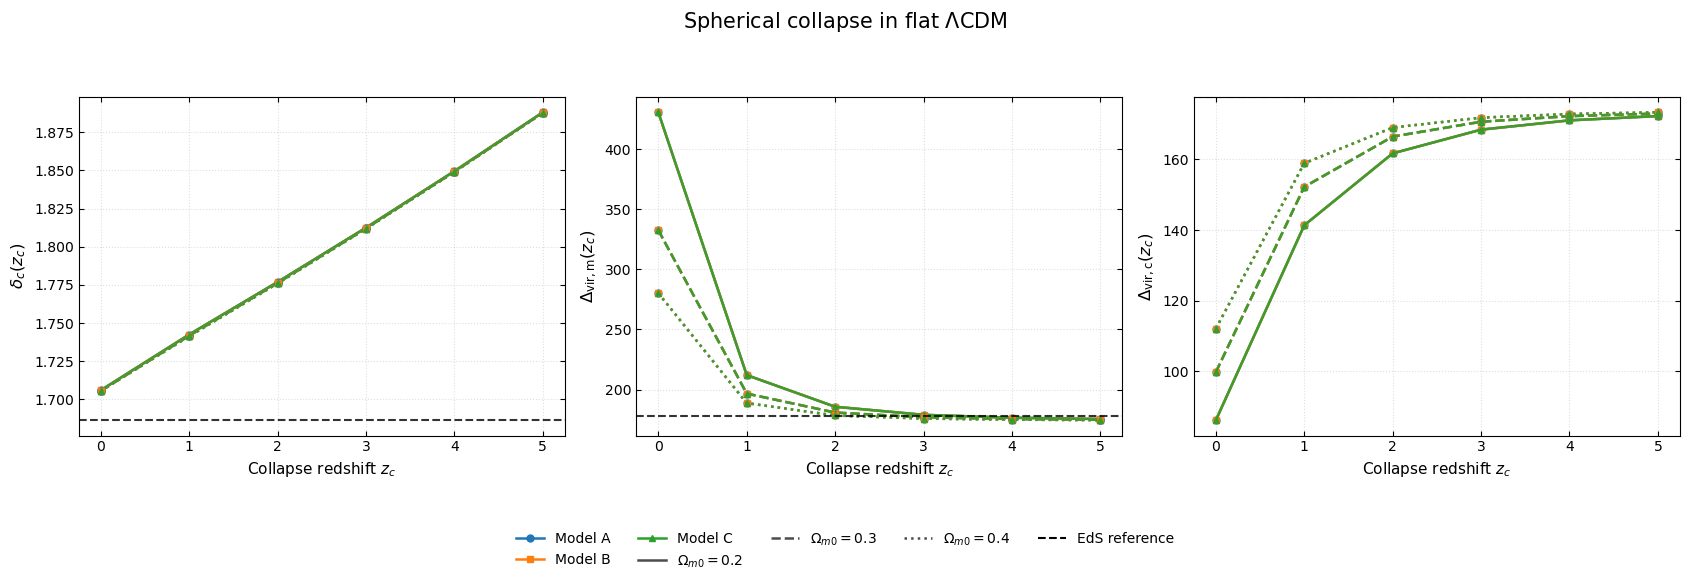

In [17]:
# Define the observables and their analytical Einstein-de Sitter (EdS) reference values.
plot_specs = [
    (
        "delta_c",
        r"$\delta_c(z_c)$",
        delta_c_eds,
        r"EdS: $\delta_c \simeq 1.68647$",
    ),
    (
        "Delta_vir_m",
        r"$\Delta_{\mathrm{vir,m}}(z_c)$",
        Delta_vir_eds,
        r"EdS: $\Delta_{\mathrm{vir}}=18\pi^2$",
    ),
    (
        "Delta_vir_c",
        r"$\Delta_{\mathrm{vir,c}}(z_c)$",
        Delta_vir_eds,
        r"EdS: $\Delta_{\mathrm{vir}}=18\pi^2$",
    ),
]

model_colors = {
    "A": "tab:blue",
    "B": "tab:orange",
    "C": "tab:green",
}

model_markers = {
    "A": "o",
    "B": "s",
    "C": "^",
}

line_styles = ["-", "--", ":", "-."]


omega_styles = {
    value: line_styles[i % len(line_styles)]
    for i, value in enumerate(Omega_m0_values)
}


fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.5),
    sharex=True,
)

# Plot each observable for all cosmologies and collapse models.
for ax, (column, ylabel, baseline, baseline_label) in zip(axes, plot_specs):
    for Omega_m0 in Omega_m0_values:
        for model in models:
            # Select the results for the current cosmology and collapse model.
            subset = grid_df[
                np.isclose(grid_df["Omega_m0"], Omega_m0)
                & (grid_df["Model"] == model)
            ].sort_values("z_c")

            if subset.empty:
                continue

            # Plot the observable as a function of the collapse redshift.
            ax.plot(
                subset["z_c"],
                subset[column],
                color=model_colors.get(model, "black"),
                linestyle=omega_styles[Omega_m0],
                marker=model_markers.get(model, "o"),
                markersize=5,
                linewidth=1.8,
                alpha=0.9,
            )

    # Add the analytical EdS benchmark as a horizontal reference line.
    ax.axhline(
        baseline,
        color="black",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label=baseline_label,
    )

    ax.set_xlabel(r"Collapse redshift $z_c$", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xticks(sorted(redshifts))
    ax.grid(True, linestyle=":", alpha=0.4)
    ax.tick_params(direction="in", top=True, right=True)
    ax.set_axisbelow(True)


model_handles = [
    Line2D(
        [0], [0],
        color=model_colors[model],
        marker=model_markers[model],
        linestyle="-",
        linewidth=1.8,
        markersize=5,
        label=f"Model {model}",
    )
    for model in models if model in model_colors
]

omega_handles = [
    Line2D(
        [0], [0],
        color="0.3",
        linestyle=omega_styles[value],
        linewidth=1.8,
        label=rf"$\Omega_{{m0}}={value:g}$",
    )
    for value in Omega_m0_values
]


reference_handle = Line2D(
    [0], [0],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="EdS reference",)


fig.legend(
    handles=model_handles + omega_handles + [reference_handle],
    loc="lower center",
    ncol=min(5, len(model_handles) + len(omega_handles) + 1),
    frameon=False,
    bbox_to_anchor=(0.5, -0.02),)

fig.suptitle(
    r"Spherical collapse in flat $\Lambda$CDM",
    fontsize=15,
    y=1.02,
)


fig.tight_layout(rect=[0, 0.14, 1, 0.96])

# Display the completed figure.
plt.show()

In [18]:
# Convergence tests in EdS
convergence_results = []

# Initialize the EdS cosmology, with all matter and no cosmological constant.
cosmology_eds = FLRW(
    h=0.67,
    Omega_m=1.0,
    Omega_lambda=0.0,
    Omega_r=0.0,
    w0_fld=-1.0,
    wa_fld=0.0,
)

a_grid = np.geomspace(1e-7, 1.0, 3000)
N_grid = np.log(a_grid)

# Solve for the linear growth factor and its evolution in the EdS cosmology.
growth_eds = cosmology_eds.solve_growth(
    N=N_grid,
    y0=[1e-7, 1e-7],
    rtol=1e-11,
    atol=1e-13,
)

if not growth_eds.success:
    raise RuntimeError(growth_eds.message)

# Initialize the spherical-collapse solver for the EdS cosmology.
collapse_eds = SphericalCollapse(cosmology=cosmology_eds)

# Vary one numerical setting at a time.
convergence_cases = []

for ai_test in [1e-3, 1e-4, 1e-5]:
    convergence_cases.append(
        ("ai", ai_test, ai_test, 1e5, 1e-8, 1e-10)
    )

for rtol_test, atol_test in [
    (1e-6, 1e-8),
    (1e-8, 1e-10),
    (1e-10, 1e-12),
]:
    convergence_cases.append(
        ("tolerance", rtol_test, 1e-3, 1e5,
         rtol_test, atol_test)
    )

for delta_stop_test in [1e5, 1e6, 1e7, 1e8]:
    convergence_cases.append(
        ("delta_stop", delta_stop_test, 1e-3,
         delta_stop_test, 1e-8, 1e-10)
    )
    
# Repeat the convergence tests for every collapse model and target redshift.
for model in models:
    for z_c in redshifts:
        for varied_parameter, setting, ai_test, stop_test, rtol_test, atol_test in convergence_cases:

            f_i = growth_rate(cosmology_eds, growth_eds, ai_test)

            # Configure the collapse-threshold solver with the current numerical settings.
            threshold = CollapseThreshold(
                collapse=collapse_eds,
                model=model,
                ai=ai_test,
                delta_stop=stop_test,
                f_i=f_i,
                n_points=1500,
                delta_i_min=1e-10,
                delta_i_max=1e-2,
                tol=1e-10,
                max_iter=150,
                rtol=rtol_test,
                atol=atol_test,
            )

            # Retune delta_i for every setting.
            delta_i, delta_c = threshold.find(z_c)
            vir = threshold.virial_overdensity(delta_i, z_c)

            a_c = 1.0 / (1.0 + z_c)

            convergence_results.append({
                "Model": model,
                "z_c": z_c,
                "varied_parameter": varied_parameter,
                "setting": setting,
                "ai": ai_test,
                "delta_stop": stop_test,
                "rtol": rtol_test,
                "atol": atol_test,
                "delta_i": delta_i,
                "delta_c": delta_c,
                "delta_c_error": delta_c - delta_c_eds,
                "a_ta/a_c": vir["a_ta"] / a_c,
                "zeta_ta": vir["zeta_ta"],
                "y_vir": vir["y_vir"],
                "Delta_vir_m": vir["Delta_vir_m"],
                "Delta_vir_m_error": (
                    vir["Delta_vir_m"] - Delta_vir_eds
                ),
                "Delta_vir_c": vir["Delta_vir_c"],
                "Delta_vir_c_error": (
                    vir["Delta_vir_c"] - Delta_vir_eds
                ),
                "turnaround_residual": vir["event_residual"],
                "Omega_m0": 1,
                "Omega_Lambda0": 0,
            })

convergence_df = pd.DataFrame(convergence_results)

#print("\n Convergence table")
#print(convergence_df.to_string(index=False))

# Maximum errors and turnaround residuals.
print("\nMaximum absolute residuals by model:")
print(
    convergence_df.groupby("Model")[
        [
            "delta_c_error",
            "Delta_vir_m_error",
            "Delta_vir_c_error",
            "turnaround_residual",
        ]
    ].agg(lambda x: x.abs().max())
)


Maximum absolute residuals by model:
       delta_c_error  Delta_vir_m_error  Delta_vir_c_error  \
Model                                                        
A           0.019429           1.139117           1.139117   
B           0.019429           1.139117           1.139117   
C           0.019429           1.139117           1.139117   

       turnaround_residual  
Model                       
A             4.440892e-15  
B             5.329071e-15  
C             5.329071e-15  


In [19]:
# Independent audit of the virial formulas and event diagnostics

# Recompute the virial overdensities from their defining relations.
audit = grid_df.copy()
audit["a_c"] = 1.0 / (1.0 + audit["z_c"])

audit["Delta_vir_m_recomputed"] = (
    audit["zeta_ta"]
    * (audit["a_c"] / audit["a_ta"])**3
    / audit["y_vir"]**3
)

audit["Omega_m_ac"] = audit.apply(
    lambda r: r["Omega_m0"] / (
        r["Omega_m0"] + (1.0 - r["Omega_m0"]) * r["a_c"]**3
    ),
    axis=1,
)

audit["Delta_vir_c_recomputed"] = (audit["Omega_m_ac"] * audit["Delta_vir_m_recomputed"])

audit["Delta_m_formula_error"] = (audit["Delta_vir_m"] - audit["Delta_vir_m_recomputed"])
audit["Delta_c_formula_error"] = (audit["Delta_vir_c"] - audit["Delta_vir_c_recomputed"])

# Recompute the virial cubic residual using the polynomial convention
# 4 lambda y^3 - 2(1 + lambda)y + 1 = 0.
audit["virial_polynomial_residual"] = (
    4.0 * audit["lambda_ta"] * audit["y_vir"]**3
    - 2.0 * (1.0 + audit["lambda_ta"]) * audit["y_vir"]
    + 1.0
)

# Compare the numerical virial solution with the independently calculated root.
audit["y_root_difference"] = (audit["y_vir"] - audit["y_root_polynomial"])
audit["y_branch_ok"] = (
    (audit["y_root_polynomial"] > 0.0)
    & (audit["y_root_polynomial"] <= 0.5 + 1e-10)
)
audit["y_matches_root"] = (np.abs(audit["y_root_difference"]) <= 1e-5)

event_residual_tol = 1e-5
formula_tol = 1e-6
polynomial_tol = 1e-5

# Summarize the audit results.
audit_summary = pd.DataFrame([
    {
        "check": "All grid observables finite",
        "passed": np.isfinite(
            audit[["delta_c", "Delta_vir_m", "Delta_vir_c"]].to_numpy()
        ).all(),
        "max_abs_residual": np.nan,
    },
    {
        "check": "Matter-referenced virial formula",
        "passed": np.isfinite(audit["Delta_m_formula_error"]).all()
        and np.max(np.abs(audit["Delta_m_formula_error"])) <= formula_tol,
        "max_abs_residual": np.max(
            np.abs(audit["Delta_m_formula_error"])
        ),
    },
    {
        "check": "Critical-referenced virial formula",
        "passed": np.isfinite(audit["Delta_c_formula_error"]).all()
        and np.max(np.abs(audit["Delta_c_formula_error"])) <= formula_tol,
        "max_abs_residual": np.max(
            np.abs(audit["Delta_c_formula_error"])
        ),
    },
    {
        "check": "Virial cubic residual",
        "passed": np.isfinite(
            audit["virial_polynomial_residual"]
        ).all()
        and np.max(np.abs(audit["virial_polynomial_residual"]))
        <= polynomial_tol,
        "max_abs_residual": np.max(
            np.abs(audit["virial_polynomial_residual"])
        ),
    },
    {
        "check": "Physical root matches y_vir",
        "passed": bool(audit["y_matches_root"].all()),
        "max_abs_residual": np.max(
            np.abs(audit["y_root_difference"])
        ),
    },
    {
        "check": "Physical root on EdS-connected branch",
        "passed": bool(audit["y_branch_ok"].all()),
        "max_abs_residual": np.nan,
    },
    {
        "check": "Turnaround event residual below configured tolerance",
        "passed": np.isfinite(
            audit["turnaround_residual"]
        ).all()
        and np.max(np.abs(audit["turnaround_residual"]))
        <= event_residual_tol,
        "max_abs_residual": np.max(
            np.abs(audit["turnaround_residual"])
        ),
    },
])

print("Independent flat-Lambda audit:")
display(audit_summary)

print("Per-case formula audit:")
display(audit[
    [
        "Omega_m0", "Model", "z_c", "a_ta", "zeta_ta",
        "lambda_ta", "y_vir", "y_root_polynomial",
        "virial_polynomial_residual", "y_root_difference",
        "Delta_m_formula_error", "Delta_c_formula_error",
        "turnaround_residual",
    ]
])

# Stop if any algebraic or physical-root check fails.
algebraic_checks = [
    "All grid observables finite",
    "Matter-referenced virial formula",
    "Critical-referenced virial formula",
    "Virial cubic residual",
    "Physical root matches y_vir",
    "Physical root on EdS-connected branch",
]

assert audit_summary.loc[
    audit_summary["check"].isin(algebraic_checks), "passed"
].all(), (
    "At least one algebraic or physical-root audit failed; "
    "inspect audit_summary."
)


Independent flat-Lambda audit:


,check,passed,max_abs_residual
0,All grid observables finite,True,NaN
1,Matter-referenced virial formula,True,5.684342e-14
2,Critical-referenced virial formula,True,1.136868e-13
3,Virial cubic residual,True,6.616929e-14
4,Physical root matches y_vir,True,3.308465e-14
5,Physical root on EdS-connected branch,True,NaN
6,Turnaround event residual below configured tol...,True,4.884981e-15


Per-case formula audit:


,Omega_m0,Model,z_c,a_ta,zeta_ta,lambda_ta,y_vir,y_root_polynomial,virial_polynomial_residual,y_root_difference,Delta_m_formula_error,Delta_c_formula_error,turnaround_residual
0,0.2,A,0,0.542741,7.511859,0.085131,0.477899,0.477899,-3.330669e-15,1.831868e-15,0.000000e+00,0.000000e+00,-4.440892e-16
1,0.2,A,1,0.306349,5.918526,0.019431,0.495096,0.495096,4.596323e-14,-2.325917e-14,0.000000e+00,0.000000e+00,-1.776357e-15
2,0.2,A,2,0.209034,5.669125,0.006445,0.498384,0.498384,0.000000e+00,-5.551115e-17,-2.842171e-14,2.842171e-14,0.000000e+00
3,0.2,A,3,0.157795,5.602407,0.002805,0.499298,0.499298,0.000000e+00,-5.551115e-17,0.000000e+00,0.000000e+00,1.332268e-15
4,0.2,A,4,0.126540,5.578085,0.001453,0.499636,0.499636,0.000000e+00,-1.110223e-16,0.000000e+00,-5.684342e-14,3.108624e-15
5,0.2,A,5,0.105565,5.567420,0.000845,0.499789,0.499789,6.405987e-14,-3.219647e-14,2.842171e-14,2.842171e-14,-2.220446e-15
6,0.2,B,0,0.542741,7.511859,0.085131,0.477899,0.477899,-3.774758e-15,1.942890e-15,0.000000e+00,0.000000e+00,-4.440892e-16
7,0.2,B,1,0.306349,5.918526,0.019431,0.495096,0.495096,4.596323e-14,-2.314815e-14,0.000000e+00,0.000000e+00,-8.881784e-16
8,0.2,B,2,0.209034,5.669125,0.006445,0.498384,0.498384,0.000000e+00,1.110223e-16,2.842171e-14,8.526513e-14,0.000000e+00
9,0.2,B,3,0.157795,5.602407,0.002805,0.499298,0.499298,0.000000e+00,1.110223e-16,0.000000e+00,0.000000e+00,0.000000e+00


EdS benchmark residuals:


,Model,z_c,delta_c_error,a_ta/a_c_error,zeta_ta_error,Delta_vir_m_error,Delta_vir_c_error,turnaround_residual,virial_polynomial_residual
0,A,0,-0.000397,0.001352,3.124523e-10,-1.139117,-1.139117,0.000000e+00,NaN
1,A,1,0.002829,0.001352,3.667846e-09,-1.139117,-1.139117,4.440892e-16,NaN
2,A,2,0.006067,0.001352,1.508127e-08,-1.139117,-1.139117,4.440892e-16,NaN
3,A,3,0.009316,0.001352,4.139952e-08,-1.139116,-1.139116,4.440892e-16,NaN
4,A,4,0.012576,0.001352,9.055441e-08,-1.139115,-1.139115,-2.220446e-15,NaN
5,A,5,0.015848,0.001352,1.716939e-07,-1.139114,-1.139114,2.664535e-15,NaN
6,B,0,-0.000397,0.001352,3.412213e-10,-1.139117,-1.139117,0.000000e+00,NaN
7,B,1,0.002829,0.001352,3.662249e-09,-1.139117,-1.139117,4.440892e-16,NaN
8,B,2,0.006067,0.001352,1.511194e-08,-1.139117,-1.139117,0.000000e+00,NaN
9,B,3,0.009316,0.001352,4.139919e-08,-1.139116,-1.139116,8.881784e-16,NaN


,Model,max_abs_delta_c_error,pass_delta_c_error,max_abs_a_ta/a_c_error,pass_a_ta/a_c_error,max_abs_zeta_ta_error,pass_zeta_ta_error,max_abs_Delta_vir_m_error,pass_Delta_vir_m_error,max_abs_Delta_vir_c_error,pass_Delta_vir_c_error,max_abs_turnaround_residual,pass_turnaround_residual,max_abs_virial_polynomial_residual,pass_virial_polynomial,PASS_ALL
0,A,0.015848,False,0.001352,True,1.716939e-07,True,1.139117,True,1.139117,True,2.664535e-15,True,NaN,False,False
1,B,0.015848,False,0.001352,True,1.717026e-07,True,1.139117,True,1.139117,True,8.881784e-16,True,NaN,False,False
2,C,0.015848,False,0.001352,True,1.716995e-07,True,1.139117,True,1.139117,True,3.108624e-15,True,NaN,False,False


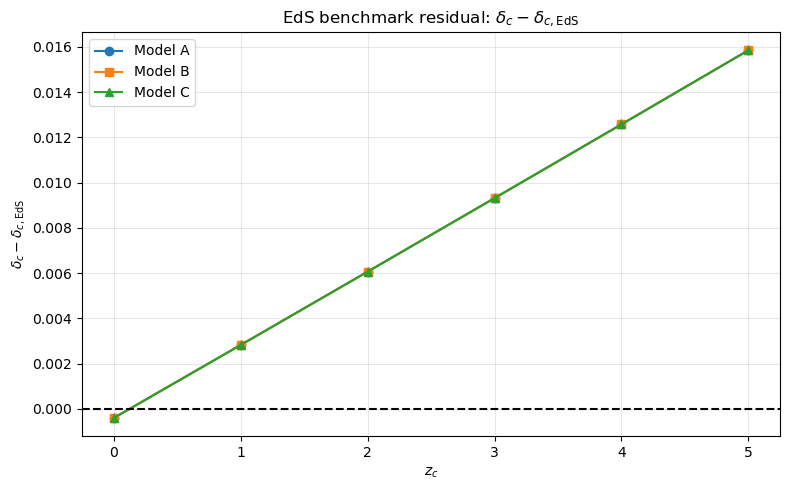

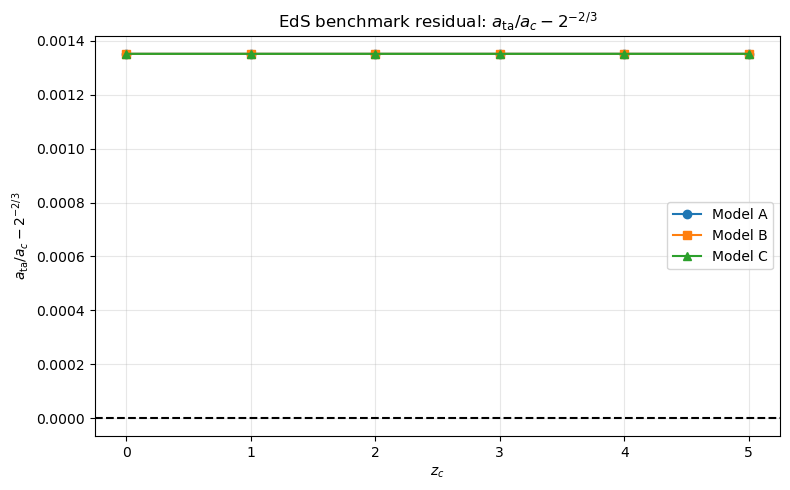

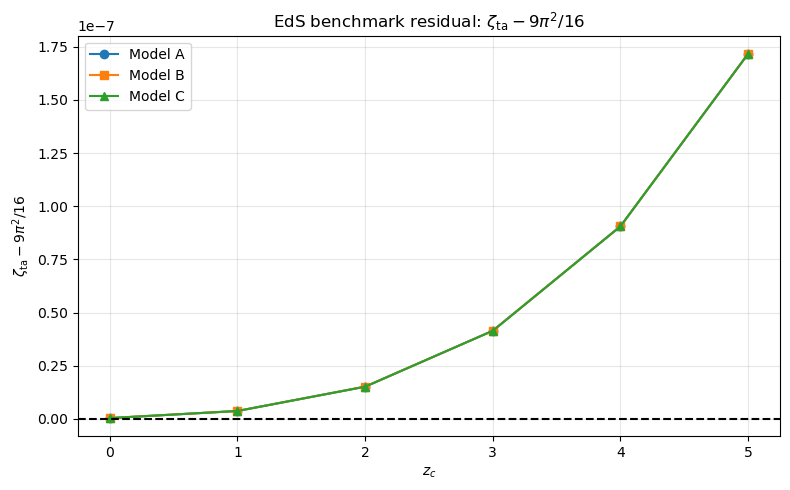

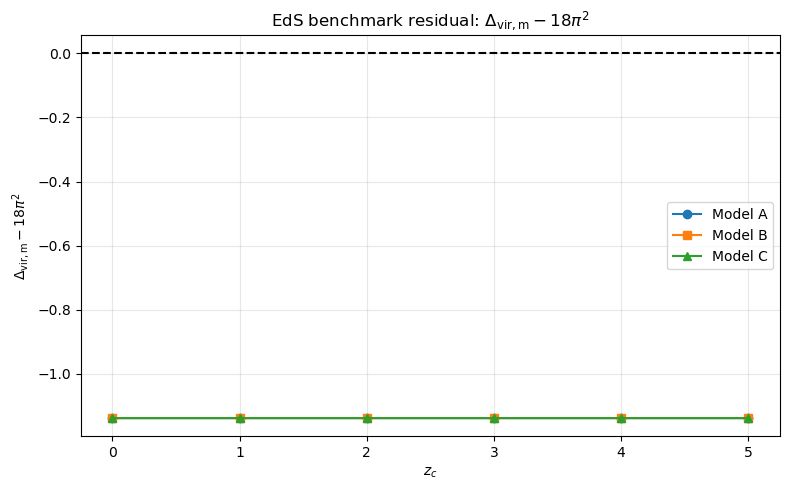

In [20]:
# (e) Independent Einstein-de Sitter benchmark checks

# Define the analytical Einstein-de Sitter (EdS) reference values.
delta_c_eds = 3.0 / 20.0 * (12.0 * np.pi)**(2.0 / 3.0)
a_ta_a_c_eds = 2.0**(-2.0 / 3.0)
zeta_ta_eds = 9.0 * np.pi**2 / 16.0
Delta_vir_eds = 18.0 * np.pi**2

# Set the numerical parameters used for the reference convergence run.
ai_ref = 1e-3
delta_stop_ref = 1e5
rtol_ref = 1e-10
atol_ref = 1e-12
setting_ref = 1e-10

reference = convergence_df.loc[
    (convergence_df["varied_parameter"] == "tolerance")
    & np.isclose(convergence_df["setting"], setting_ref, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["ai"], ai_ref, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["delta_stop"], delta_stop_ref, rtol=0, atol=1e-8)
    & np.isclose(convergence_df["rtol"], rtol_ref, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["atol"], atol_ref, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["Omega_m0"], 1.0, rtol=0, atol=1e-12)
    & np.isclose(convergence_df["Omega_Lambda0"], 0.0, rtol=0, atol=1e-12)
].copy()


counts = (
    reference.groupby(["Model", "z_c"])
    .size()
    .reindex(
        pd.MultiIndex.from_product(
            [models, redshifts], names=["Model", "z_c"]
        ),
        fill_value=0
    )
)

# Verify that the selected rows really correspond to EdS.
if {"Omega_m0", "Omega_Lambda0"}.issubset(reference.columns):
    is_eds = (
        np.isclose(reference["Omega_m0"], 1.0)
        & np.isclose(reference["Omega_Lambda0"], 0.0)
    )
    reference = reference[is_eds]
else:
    raise KeyError(
        "Cannot verify the EdS cosmology: convergence_df must contain "
        "'Omega_m0' and 'Omega_Lambda0' columns. Add them when building "
        "convergence_df rather than assuming the runs are EdS."
    )

if reference.empty:
    raise RuntimeError(
        "No EdS reference runs found at the requested tolerances. "
        "Run the EdS model separately before applying these benchmarks."
    )

benchmark_results = []

for model in models:
    for z_c in redshifts:
        subset = reference[
            (reference["Model"] == model)
            & np.isclose(reference["z_c"], z_c)
        ]

        if len(subset) != 1:
            raise RuntimeError(
                f"Expected exactly one EdS reference run for "
                f"Model {model}, z_c={z_c}; found {len(subset)}."
            )

        row = subset.iloc[0]

        benchmark_results.append({
            "Model": model,
            "z_c": z_c,
            "delta_c_error": row["delta_c"] - delta_c_eds,
            "a_ta/a_c_error": row["a_ta/a_c"] - a_ta_a_c_eds,
            "zeta_ta_error": row["zeta_ta"] - zeta_ta_eds,
            "Delta_vir_m_error": row["Delta_vir_m"] - Delta_vir_eds,
            "Delta_vir_c_error": row["Delta_vir_c"] - Delta_vir_eds,
            "turnaround_residual": row["turnaround_residual"],
            "virial_polynomial_residual": row.get(
                "virial_polynomial_residual", np.nan
            ),
        })

benchmark_df = pd.DataFrame(benchmark_results)

print("EdS benchmark residuals:")
display(benchmark_df)

# Tolerances should be justified against the integration accuracy.
benchmark_tolerances = {
    "delta_c_error": 5e-3,
    "a_ta/a_c_error": 5e-3,
    "zeta_ta_error": 5e-2,
    "Delta_vir_m_error": 2.0,
    "Delta_vir_c_error": 2.0,
    "turnaround_residual": 1e-6,
}

benchmark_checks = []

for model, sub in benchmark_df.groupby("Model"):
    result = {"Model": model}

    for col, tol in benchmark_tolerances.items():
        max_error = float(np.max(np.abs(sub[col])))
        result[f"max_abs_{col}"] = max_error
        result[f"pass_{col}"] = max_error <= tol

    # This test is reported only if the residual is available.
    if sub["virial_polynomial_residual"].notna().all():
        max_virial_residual = float(
            np.max(np.abs(sub["virial_polynomial_residual"]))
        )
        result["max_abs_virial_polynomial_residual"] = max_virial_residual
        result["pass_virial_polynomial"] = max_virial_residual <= 1e-8
    else:
        result["max_abs_virial_polynomial_residual"] = np.nan
        result["pass_virial_polynomial"] = False

    pass_columns = [
        key for key in result
        if key.startswith("pass_")
    ]
    result["PASS_ALL"] = all(result[key] for key in pass_columns)
    benchmark_checks.append(result)

benchmark_checks_df = pd.DataFrame(benchmark_checks)
display(benchmark_checks_df)

if not benchmark_checks_df["PASS_ALL"].all():
    print(
        "WARNING: At least one EdS benchmark failed or a required "
        "residual was unavailable."
    )
else:
    print("All EdS benchmark checks passed.")

# Plot the benchmark residuals.
plot_columns = [
    ("delta_c_error", r"$\delta_c-\delta_{c,\mathrm{EdS}}$"),
    ("a_ta/a_c_error", r"$a_{\mathrm{ta}}/a_c-2^{-2/3}$"),
    ("zeta_ta_error", r"$\zeta_{\mathrm{ta}}-9\pi^2/16$"),
    ("Delta_vir_m_error", r"$\Delta_{\mathrm{vir,m}}-18\pi^2$"),
]

for col, ylabel in plot_columns:
    plt.figure(figsize=(8, 5))

    for model in models:
        sub = benchmark_df[benchmark_df["Model"] == model].sort_values("z_c")
        plt.plot(
            sub["z_c"],
            sub[col],
            marker={"A": "o", "B": "s", "C": "^"}[model],
            label=f"Model {model}",
        )

    plt.axhline(0.0, color="black", linestyle="--")
    plt.xlabel(r"$z_c$")
    plt.ylabel(ylabel)
    plt.title(f"EdS benchmark residual: {ylabel}")
    plt.xticks(redshifts)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()



In [21]:
# (f) Cross-formulation differences for each cosmology and redshift

observables = ["delta_c", "Delta_vir_m", "Delta_vir_c"]

model_spread_df = (
    grid_df.groupby(["Omega_m0", "z_c"])[observables]
    .agg(lambda x: x.max() - x.min())
    .reset_index()
    .rename(columns={
        "delta_c": "spread_delta_c",
        "Delta_vir_m": "spread_Delta_vir_m",
        "Delta_vir_c": "spread_Delta_vir_c",
    })
)

print("Spread across Models A, B, and C:")
print(model_spread_df.to_string(index=False))

# Basic completeness and validity checks
assert len(grid_df) == len(Omega_m0_values) * len(redshifts) * len(models)
assert not grid_df[observables].isna().any().any()
assert np.isfinite(grid_df[observables].to_numpy()).all()

print("All expected grid results are present and finite.")


if {"y_vir", "y_root_polynomial"}.issubset(grid_df.columns):
    grid_df["y_root_difference"] = grid_df["y_vir"] - grid_df["y_root_polynomial"]
    print("Virial radius ratio: library value versus physical polynomial root")
    display(grid_df[["Omega_m0", "Model", "z_c", "lambda_ta",
                     "y_vir", "y_root_polynomial", "y_root_difference"]])


Spread across Models A, B, and C:
 Omega_m0  z_c  spread_delta_c  spread_Delta_vir_m  spread_Delta_vir_c
      0.2    0    6.526317e-10        5.426345e-07        1.085269e-07
      0.2    1    8.575116e-10        3.103231e-07        2.068820e-07
      0.2    2    1.067677e-09        3.157436e-07        2.750025e-07
      0.2    3    9.156227e-10        2.531833e-07        2.382902e-07
      0.2    4    9.238266e-10        2.407534e-07        2.332881e-07
      0.2    5    1.079977e-09        2.685752e-07        2.636920e-07
      0.3    0    8.188183e-10        5.074586e-07        1.522376e-07
      0.3    1    8.894705e-10        2.934873e-07        2.272160e-07
      0.3    2    9.195760e-10        2.653247e-07        2.442193e-07
      0.3    3    9.290551e-10        2.511279e-07        2.422942e-07
      0.3    4    1.043856e-09        2.637718e-07        2.589383e-07
      0.3    5    9.338528e-10        2.296640e-07        2.272096e-07
      0.4    0    8.725236e-10        4.447

,Omega_m0,Model,z_c,lambda_ta,y_vir,y_root_polynomial,y_root_difference
0,0.2,A,0,0.085131,0.477899,0.477899,1.831868e-15
1,0.2,A,1,0.019431,0.495096,0.495096,-2.325917e-14
2,0.2,A,2,0.006445,0.498384,0.498384,-5.551115e-17
3,0.2,A,3,0.002805,0.499298,0.499298,-5.551115e-17
4,0.2,A,4,0.001453,0.499636,0.499636,-1.110223e-16
5,0.2,A,5,0.000845,0.499789,0.499789,-3.219647e-14
6,0.2,B,0,0.085131,0.477899,0.477899,1.942890e-15
7,0.2,B,1,0.019431,0.495096,0.495096,-2.314815e-14
8,0.2,B,2,0.006445,0.498384,0.498384,1.110223e-16
9,0.2,B,3,0.002805,0.499298,0.499298,1.110223e-16


Convergence relative to tight-tolerance reference:
Model  z_c varied_parameter      setting  delta_c_change  Delta_vir_m_change  Delta_vir_c_change
    A    0               ai 1.000000e-03        0.000000        0.000000e+00        0.000000e+00
    A    0               ai 1.000000e-04       -0.002894       -4.666882e-08       -4.666882e-08
    A    0               ai 1.000000e-05       -0.003183       -6.702103e-08       -6.702103e-08
    A    0        tolerance 1.000000e-06        0.000000        0.000000e+00        0.000000e+00
    A    0        tolerance 1.000000e-08        0.000000        0.000000e+00        0.000000e+00
    A    0        tolerance 1.000000e-10        0.000000        0.000000e+00        0.000000e+00
    A    0       delta_stop 1.000000e+05        0.000000        0.000000e+00        0.000000e+00
    A    0       delta_stop 1.000000e+06        0.002489        7.813126e-01        7.813126e-01
    A    0       delta_stop 1.000000e+07        0.003268        1.026370e+00

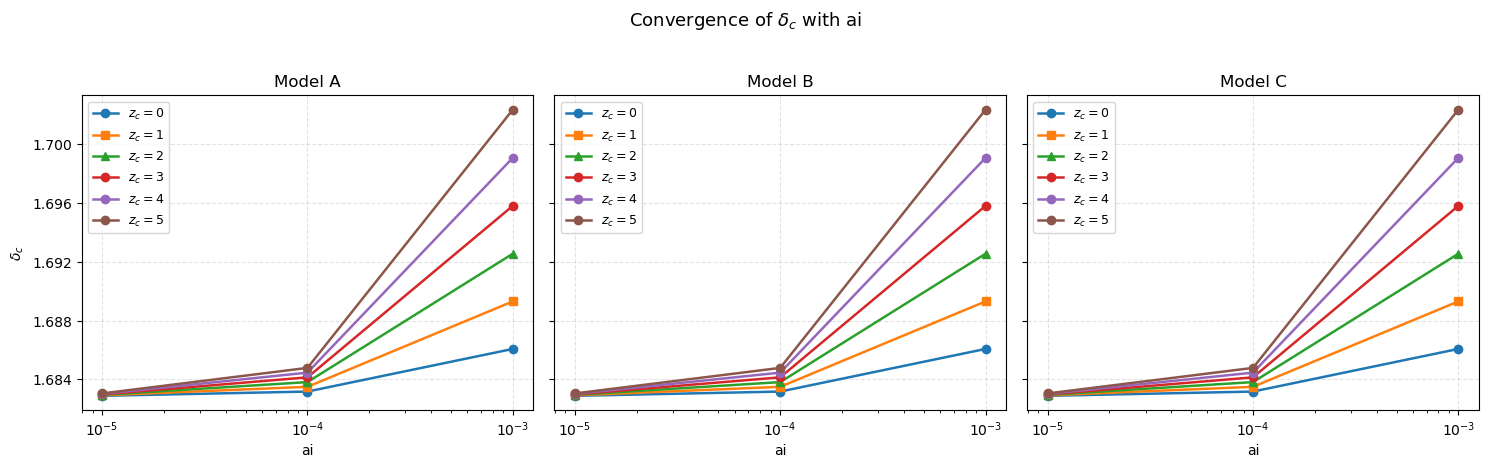

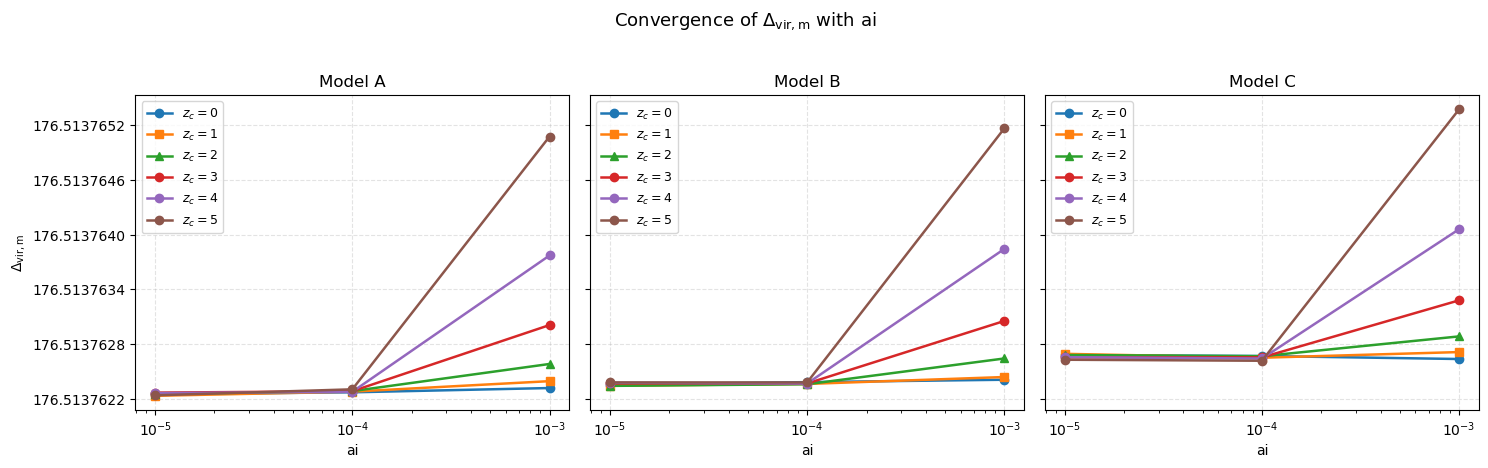

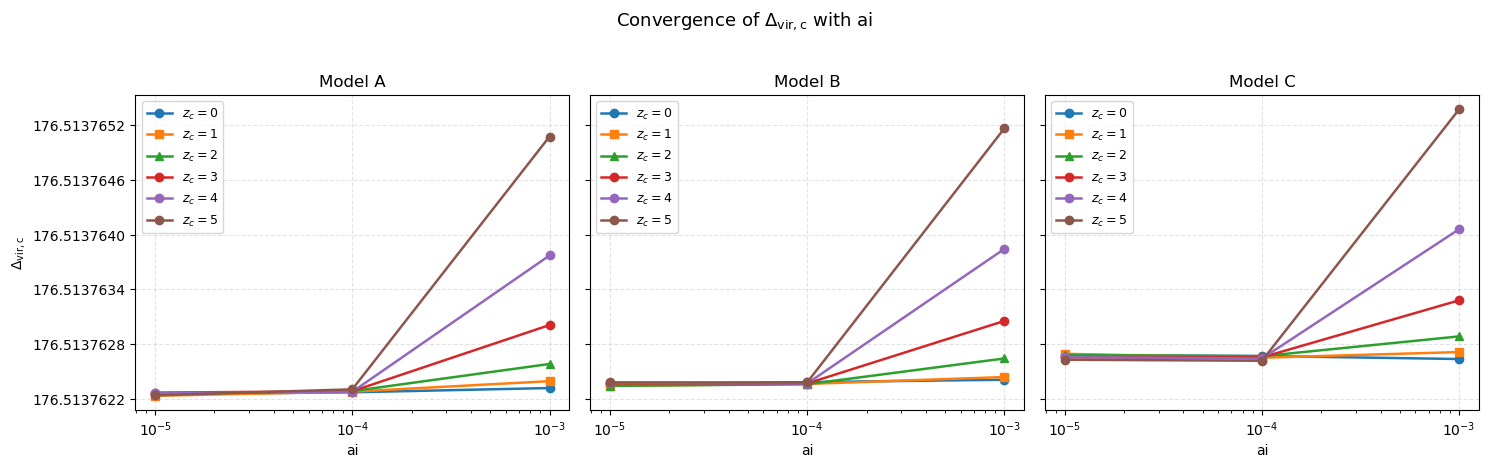

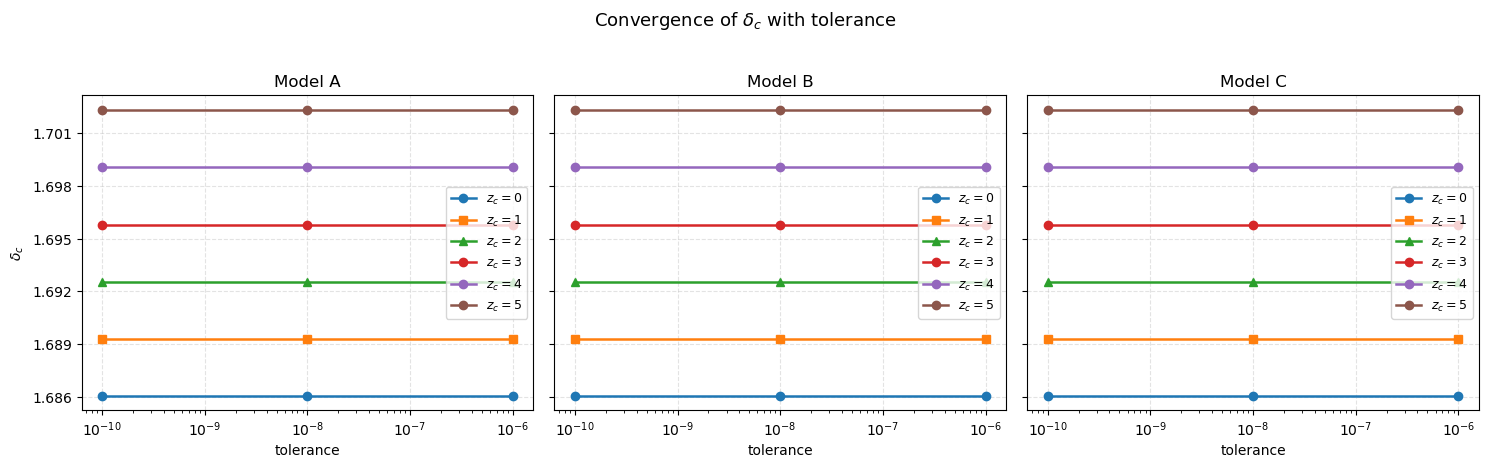

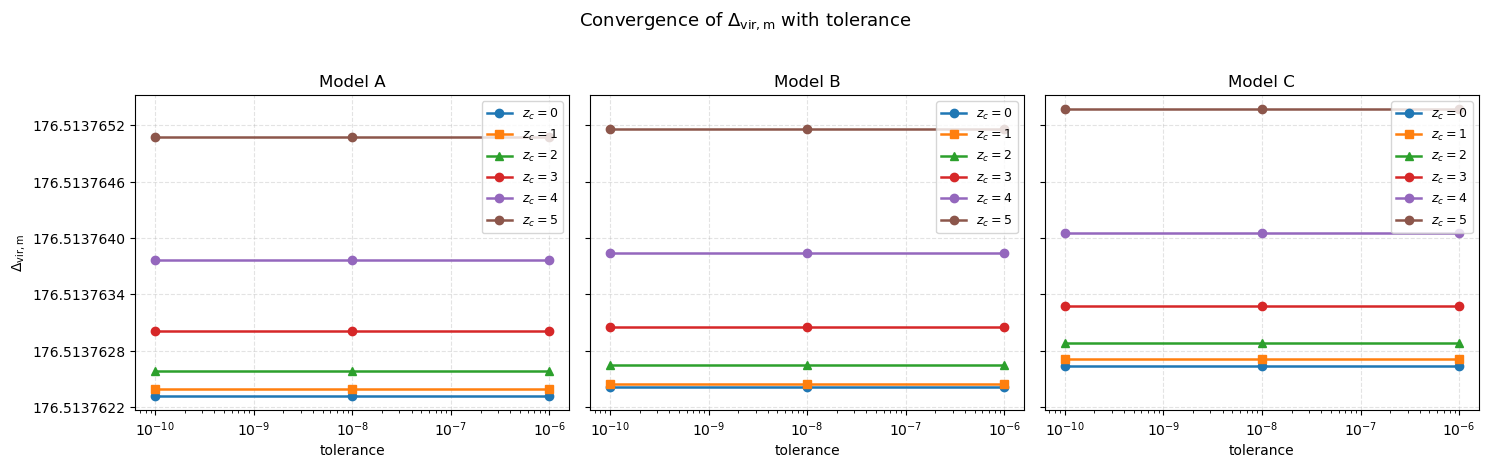

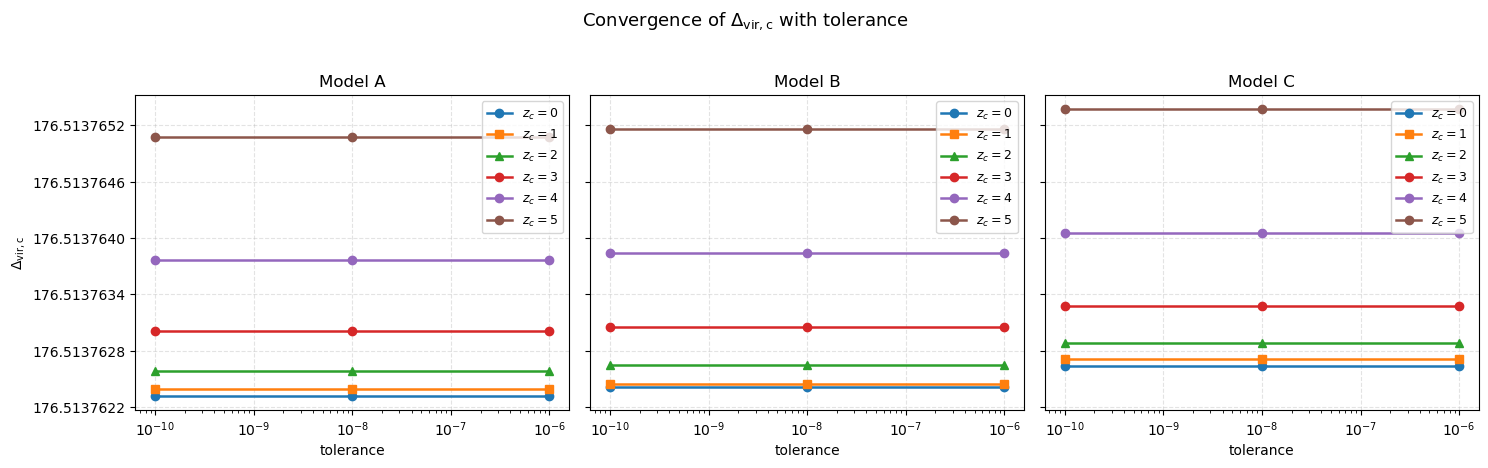

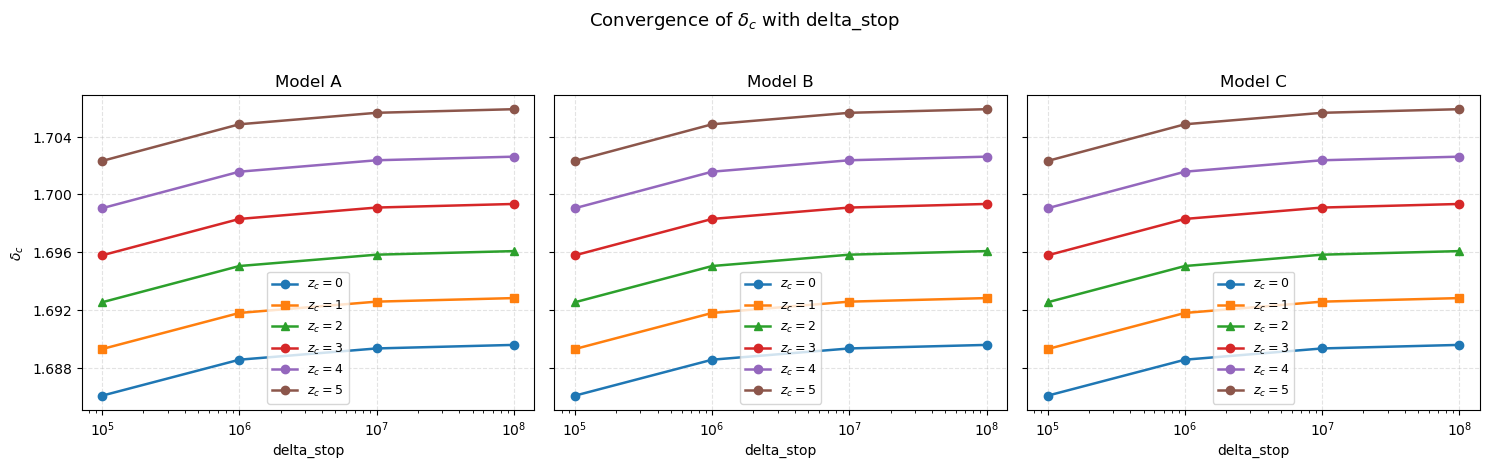

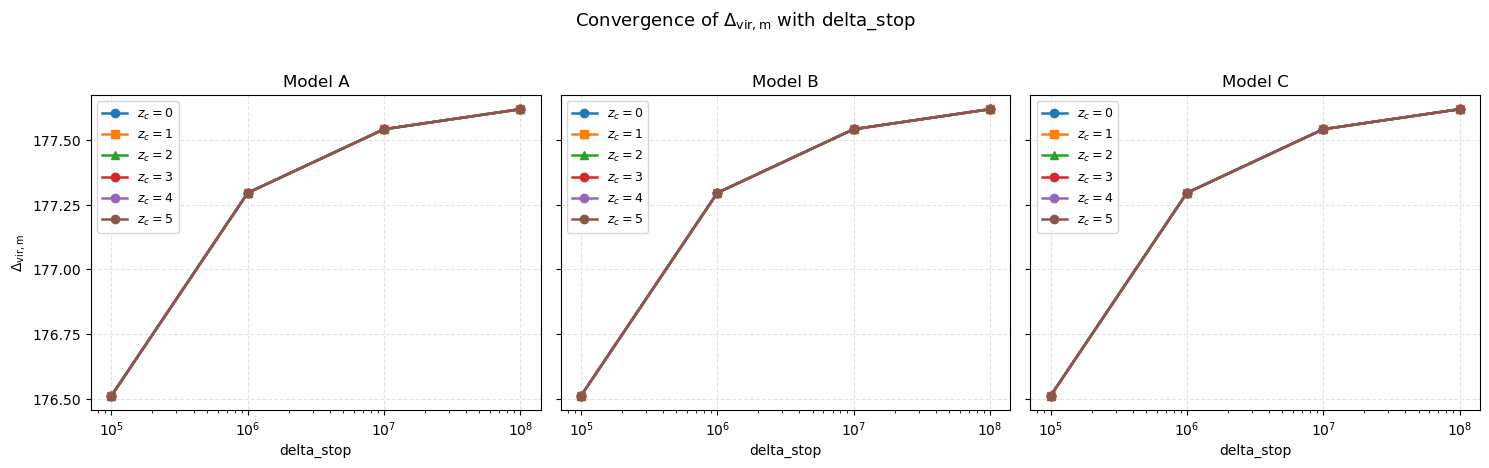

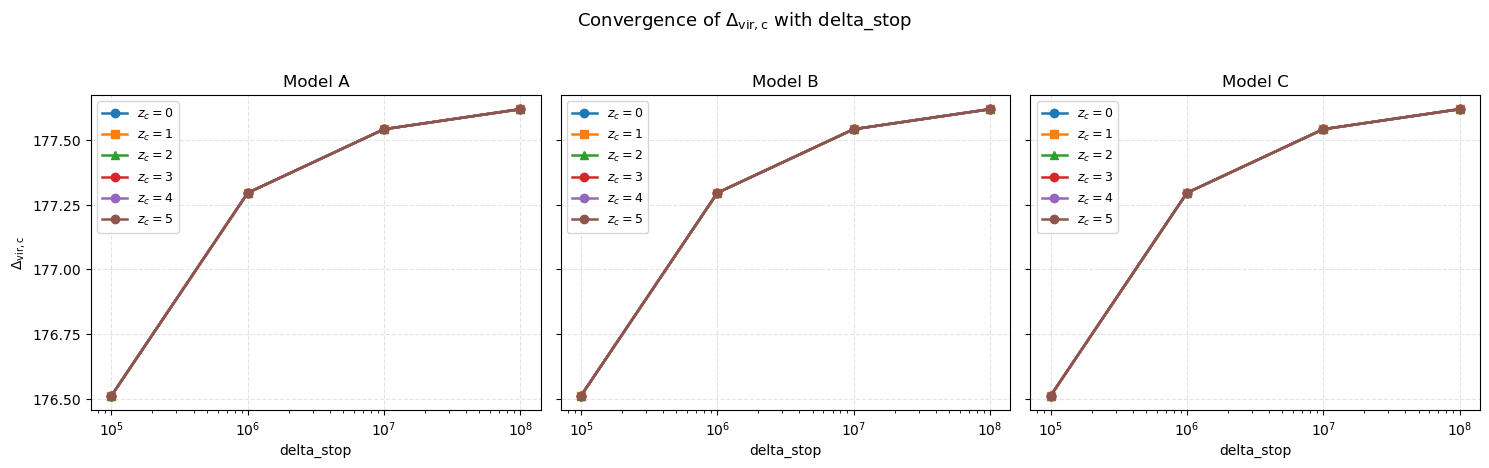

,check,passed
0,Turnaround and virial quantities recorded,True
1,Virial root comparison recorded,True
2,EdS benchmark table contains all models and re...,True
3,Cosmology grid contains 27 cases,True
4,Convergence table is non-empty,True
5,Event residuals are finite,True
6,(g) Reference contains one row per model and r...,True


In [22]:
# (g) Changes relative to the tight-tolerance reference

# Select exactly one tight-tolerance reference run for each model and redshift.
reference = convergence_df[
    (convergence_df["varied_parameter"] == "tolerance")
    & np.isclose(convergence_df["setting"], 1e-10, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["rtol"], 1e-10, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["atol"], 1e-12, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["ai"], 1e-3, rtol=0, atol=1e-15)
    & np.isclose(convergence_df["delta_stop"], 1e5, rtol=0, atol=1e-8)
    & np.isclose(convergence_df["Omega_m0"], 1.0, rtol=0, atol=1e-12)
    & np.isclose(convergence_df["Omega_Lambda0"], 0.0, rtol=0, atol=1e-12)
][[
    "Model", "z_c", "delta_c", "Delta_vir_m", "Delta_vir_c"
]].rename(columns={
    "delta_c": "delta_c_ref",
    "Delta_vir_m": "Delta_vir_m_ref",
    "Delta_vir_c": "Delta_vir_c_ref",
})

# Verify that each model-redshift combination has exactly one reference.
expected_index = pd.MultiIndex.from_product([models, redshifts], names=["Model", "z_c"])

reference_counts = (
    reference.groupby(["Model", "z_c"])
    .size()
    .reindex(expected_index, fill_value=0)
)

# Merge the reference values into the convergence table.
convergence_comparison = convergence_df.merge(
    reference,
    on=["Model", "z_c"],
    how="left",
    validate="many_to_one",
)

# Calculate changes relative to the reference.
for quantity in ["delta_c", "Delta_vir_m", "Delta_vir_c"]:
    convergence_comparison[f"{quantity}_change"] = (
        convergence_comparison[quantity]
        - convergence_comparison[f"{quantity}_ref"]
    )

print("Convergence relative to tight-tolerance reference:")
print(convergence_comparison[
    [
        "Model", "z_c", "varied_parameter", "setting",
        "delta_c_change", "Delta_vir_m_change",
        "Delta_vir_c_change",
    ]
].to_string(index=False))


# Plot convergence for the three observables, grouped by varied parameter.
for varied in ["ai", "tolerance", "delta_stop"]:
    subset_all = convergence_df[
        convergence_df["varied_parameter"] == varied
    ].copy()

    for observable, ylabel in [
        ("delta_c", r"$\delta_c$"),
        ("Delta_vir_m", r"$\Delta_{\mathrm{vir,m}}$"),
        ("Delta_vir_c", r"$\Delta_{\mathrm{vir,c}}$"),
    ]:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

        for ax, model in zip(axes, models):
            model_data = subset_all[subset_all["Model"] == model]
            for z_c in redshifts:
                subset = model_data[model_data["z_c"] == z_c].sort_values("setting")

                if subset.empty:
                    continue

                x = subset["setting"].to_numpy()
                y = subset[observable].to_numpy()

                ax.plot(
                    x, y,
                    marker={0: "o", 1: "s", 2: "^"}.get(z_c, "o"),
                    linewidth=1.8,
                    markersize=6,
                    label=fr"$z_c={z_c}$",
                )

            ax.set_title(f"Model {model}")
            ax.set_xlabel(varied)
            ax.grid(True, linestyle="--", alpha=0.35)
            ax.legend(fontsize=9)

            # Use a logarithmic x-axis for positive numerical settings.
            if len(model_data) and (model_data["setting"] > 0).all():
                ax.set_xscale("log")

        axes[0].set_ylabel(ylabel)

        # Disable the additive offset that obscures small differences.
        formatter = ScalarFormatter(useOffset=False)
        formatter.set_scientific(False)

        for ax in axes:
            ax.yaxis.set_major_formatter(formatter)
            ax.yaxis.set_major_locator(MaxNLocator(6))

        fig.suptitle(
            f"Convergence of {ylabel} with {varied}",
            fontsize=13,
            y=1.03,
        )
        fig.tight_layout()
        plt.show()


# Run the final checklist.
checks = [
    ( "Turnaround and virial quantities recorded",
        all(
            c in grid_df.columns
            for c in ["a_ta", "zeta_ta", "y_vir","Delta_vir_m", "Delta_vir_c",]),),
    
    ("Virial root comparison recorded","y_root_polynomial" in grid_df.columns,),
    
    ("EdS benchmark table contains all models and redshifts",len(benchmark_df) == len(models) * len(redshifts),),
    
    ("Cosmology grid contains 27 cases",len(grid_df)== len(Omega_m0_values) * len(redshifts) * len(models),),
    
    ("Convergence table is non-empty",len(convergence_df) > 0,),
    
    ("Event residuals are finite",np.isfinite(convergence_df["turnaround_residual"].to_numpy()).all(),),
    
    ("(g) Reference contains one row per model and redshift",
        len(reference) == len(models) * len(redshifts)
        and (reference_counts == 1).all(),),
]

checks_df = pd.DataFrame(checks, columns=["check", "passed"])
display(checks_df)

# Report potential numerical failure modes for inspection.
# Potential numerical failure modes to inspect:
# - A: theta = -delta_N/(1+delta) is ill-conditioned
#   if 1+delta is very small.
# - B: Direct theta integration may lose accuracy near formal collapse.
# - C: delta = 1/g amplifies relative errors as g approaches zero.
# These are diagnostic possibilities, not assertions that a failure occurred.

In [25]:
# Cross-formulation spread for each convergence configuration

convergence_spread_df = (
    convergence_df.groupby(
        ["z_c", "varied_parameter", "setting",
         "ai", "delta_stop", "rtol", "atol"]
    )[["delta_c", "Delta_vir_m", "Delta_vir_c"]]
    .agg(lambda x: x.max() - x.min())
    .reset_index()
    .rename(columns={
        "delta_c": "spread_delta_c",
        "Delta_vir_m": "spread_Delta_vir_m",
        "Delta_vir_c": "spread_Delta_vir_c",
    })
)

print("Cross-formulation convergence differences:")
print(convergence_spread_df.to_string(index=False))


Cross-formulation convergence differences:
 z_c varied_parameter      setting      ai  delta_stop         rtol         atol  spread_delta_c  spread_Delta_vir_m  spread_Delta_vir_c
   0               ai 1.000000e-05 0.00001    100000.0 1.000000e-08 1.000000e-10    1.434157e-09        4.263474e-07        4.263474e-07
   0               ai 1.000000e-04 0.00010    100000.0 1.000000e-08 1.000000e-10    1.291180e-09        3.966177e-07        3.966177e-07
   0               ai 1.000000e-03 0.00100    100000.0 1.000000e-08 1.000000e-10    9.936214e-10        3.168030e-07        3.168030e-07
   0       delta_stop 1.000000e+05 0.00100    100000.0 1.000000e-08 1.000000e-10    9.936214e-10        3.168030e-07        3.168030e-07
   0       delta_stop 1.000000e+06 0.00100   1000000.0 1.000000e-08 1.000000e-10    1.028915e-09        3.182317e-07        3.182317e-07
   0       delta_stop 1.000000e+07 0.00100  10000000.0 1.000000e-08 1.000000e-10    1.172219e-09        3.651273e-07        3.651273e-0

In [14]:
# Final validation summary

checks = [
    ("(d) Turnaround and virial quantities recorded",
        all(col in grid_df.columns
            for col in [
                "a_ta", "zeta_ta", "y_vir",
                "Delta_vir_m", "Delta_vir_c",]),),
    
    ("(d) Virial root comparison recorded","y_root_polynomial" in grid_df.columns,),
    
    ("(d) Virial audit completed","audit_summary" in globals() and audit_summary["passed"].all(),),
    
    ("(e) EdS benchmark table contains all model-redshift combinations","benchmark_df" in globals()and len(benchmark_df) == len(models) * len(redshifts),),
    
    ("(f) ACDM grid contains all expected cases",len(grid_df) == len(Omega_m0_values) * len(redshifts) * len(models),),
    
    ("(f) ACDM observables are finite",
        np.isfinite(grid_df[["delta_c", "Delta_vir_m", "Delta_vir_c"]].to_numpy()).all(),),
    
    ("(g) Turnaround residuals in convergence runs are finite",np.isfinite(convergence_df["turnaround_residual"].to_numpy()).all(),),
    
    ("(g) Convergence comparison has been generated","convergence_comparison" in globals(),),
]

checks_df = pd.DataFrame(checks, columns=["check", "passed"])
display(checks_df)

if checks_df["passed"].all():
    print("All structural and numerical validation checks passed.")
else:
    print("Some checks failed. Inspect the rows marked False before interpreting the results.")

,check,passed
0,(d) Turnaround and virial quantities recorded,True
1,(d) Virial root comparison recorded,True
2,(d) Virial audit completed,True
3,(e) EdS benchmark table contains all model-red...,True
4,(f) ACDM grid contains all expected cases,True
5,(f) ACDM observables are finite,True
6,(g) Turnaround residuals in convergence runs a...,True
7,(g) Convergence comparison has been generated,True


All structural and numerical validation checks passed.
